In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip /content/drive/MyDrive/ImageSegmentationYOLOv8_50epoch-20240217T093031Z-001.zip

In [ ]:
import os

# Klasör yolu
klasor_yolu = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/labels/val'

# Klasördeki tüm dosyaları ve klasörleri listele
for dosya in os.listdir(klasor_yolu):
    # Yeni dosya adını oluştur (eğer dosya adında '_mask' varsa kaldır)
    yeni_dosya_adi = dosya.replace('_mask', '')

    # Eski ve yeni dosya yollarını oluştur
    eski_dosya_yolu = os.path.join(klasor_yolu, dosya)
    yeni_dosya_yolu = os.path.join(klasor_yolu, yeni_dosya_adi)

    # Dosya ismini değiştir
    os.rename(eski_dosya_yolu, yeni_dosya_yolu)

    print(f"'{dosya}' isimli dosyanın yeni adı '{yeni_dosya_adi}' oldu.")


In [ ]:
len(os.listdir("/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/labels/val"))

198

In [2]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 715.0/715.0 kB 5.1 MB/s eta 0:00:00


In [3]:
DATA_DIR = "/content/drive/MyDrive/ImageSegmentationYOLOv8_50epoch/all_info"

In [4]:
from ultralytics import YOLO

In [5]:
%cd /content/drive/MyDrive/ImageSegmentationYOLOv8_50epoch

/content/drive/MyDrive/ImageSegmentationYOLOv8x


In [6]:
!ls

all_info  config.yaml


In [8]:


model = YOLO('yolov8n-seg.pt')  # load a pretrained model (recommended for training)

model.train(data='config.yaml', epochs=50, imgsz=640)

100%|██████████| 6.73M/6.73M [00:00<00:00, 92.4MB/s]


Ultralytics YOLOv8.1.14 🚀 Python-3.10.12 torch-2.1.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: task=segment, mode=train, model=yolov8n-seg.pt, data=config.yaml, epochs=50, time=None, patience=50, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, show_boxes=True,

100%|██████████| 755k/755k [00:00<00:00, 22.3MB/s]


Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

100%|██████████| 6.23M/6.23M [00:00<00:00, 94.4MB/s]


...

      50/50      2.72G      1.006      1.244     0.6209     0.8853          6        640: 100%|██████████| 50/50 [00:21<00:00,  2.34it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:03<00:00,  2.08it/s]


                   all        198        513      0.826      0.788      0.859      0.539      0.826      0.733      0.828      0.472

50 epochs completed in 0.390 hours.
Optimizer stripped from runs/segment/train/weights/last.pt, 6.8MB
Optimizer stripped from runs/segment/train/weights/best.pt, 6.8MB

Validating runs/segment/train/weights/best.pt...
Ultralytics YOLOv8.1.14 🚀 Python-3.10.12 torch-2.1.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
YOLOv8n-seg summary (fused): 195 layers, 3258259 parameters, 0 gradients, 12.0 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:08<00:00,  1.23s/it]


                   all        198        513      0.859       0.77      0.866      0.548      0.817       0.74      0.829      0.473
Speed: 0.3ms preprocess, 5.8ms inference, 0.0ms loss, 5.2ms postprocess per image
Results saved to runs/segment/train


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78dc12422aa0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [9]:
# Karışıklık matrisi değerlerine göre IoU hesaplama
TP = 432  # Doğru Pozitifler
FP = 107  # Yanlış Pozitifler
FN = 81  # Yanlış Negatifler

# IoU hesaplaması
IoU = TP / (TP + FP + FN)
IoU


0.6967741935483871

In [ ]:
from ultralytics import YOLO
import cv2
import numpy as np

model_path = '/content/drive/MyDrive/ImageSegmentationYOLOv8/runs/segment/train/weights/last.pt'
image_path = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/(103-180)0027.png'

img = cv2.imread(image_path)
H, W, _ = img.shape

model = YOLO(model_path)

results = model(img)

for result in results:
    for j, mask in enumerate(result.masks.data):
        # GPU tensorunu CPU'ya taşı ve NumPy dizisine çevir
        mask = mask.cpu().numpy() * 255

        # Maskenin boyutunu orijinal görüntü boyutuna çevir
        mask = cv2.resize(mask.astype(np.uint8), (W, H))  # Veri tipini uint8 olarak ayarla

        # Maskeyi kaydet
        cv2.imwrite(f'./output_{j}.png', mask)



0: 640x640 3 Cancers, 318.7ms
Speed: 6.7ms preprocess, 318.7ms inference, 18.9ms postprocess per image at shape (1, 3, 640, 640)


In [ ]:
import pandas as pd

# results.csv dosyasının yolu
results_path = '/content/drive/MyDrive/ImageSegmentationYOLOv8/runs/segment/train/results.csv'

# CSV dosyasını oku
results_df = pd.read_csv(results_path)

# Sonuçları yazdır
print(results_df)



0: 640x640 1 Cancer, 549.8ms
Speed: 9.2ms preprocess, 549.8ms inference, 7.8ms postprocess per image at shape (1, 3, 640, 640)


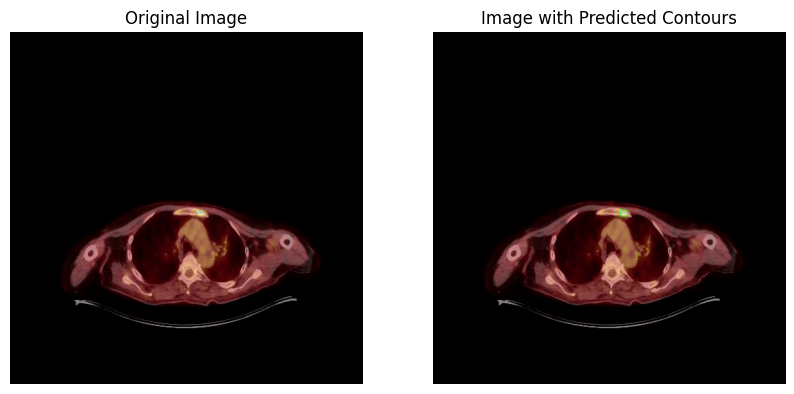

In [ ]:
import os
import numpy as np
import cv2
from matplotlib import pyplot as plt
from ultralytics import YOLO

# Modeli yükle
model = YOLO('/content/drive/MyDrive/ImageSegmentationYOLOv8/runs/segment/train/weights/last.pt')

# Doğrulama veri seti yolları
val_images_dir = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val'  # Doğrulama görüntülerinin yolu
val_labels_dir = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/labels/val'

# Rastgele bir doğrulama görüntüsü seç
val_image_files = [f for f in sorted(os.listdir(val_images_dir)) if f.endswith('.png')]
random_image_file = np.random.choice(val_image_files)
img_path = os.path.join(val_images_dir, random_image_file)
img = cv2.imread(img_path)
H, W, _ = img.shape

# Model ile tahmin yap
results = model(img)

# Orijinal görüntüyü kopyala
img_with_contours = img.copy()

# Tahmin edilen maskeleri işle ve konturları çiz
if results[0].masks is not None:
    for mask in results[0].masks.data.cpu().numpy():
        mask = (mask * 255).astype(np.uint8)  # Maske piksellerini 0 ve 1 aralığından 0 ve 255 aralığına dönüştür
        mask = cv2.resize(mask, (W, H))  # Maskeyi orijinal görüntünün boyutlarına çevir
        contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(img_with_contours, contours, -1, (0, 255, 0), 0)  # Yeşil renkli konturlar

# Orijinal görüntü ve konturlu görüntüyü görselleştir
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_with_contours, cv2.COLOR_BGR2RGB))
plt.title('Image with Predicted Contours')
plt.axis('off')

plt.show()



0: 640x640 1 Cancer, 321.2ms
Speed: 5.1ms preprocess, 321.2ms inference, 5.5ms postprocess per image at shape (1, 3, 640, 640)


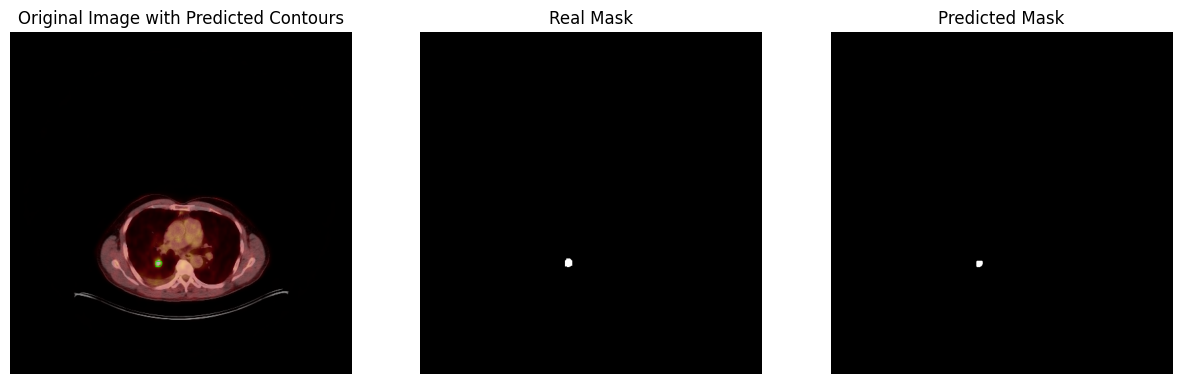

In [ ]:
import os
import numpy as np
import cv2
from matplotlib import pyplot as plt
from ultralytics import YOLO  # YOLO kütüphanesini doğru bir şekilde yüklediğinizden emin olun

# Modeli yükle
model = YOLO('/content/drive/MyDrive/ImageSegmentationYOLOv8/runs/segment/train/weights/last.pt')

# Doğrulama veri seti yolları
val_images_dir = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val'  # Doğrulama görüntülerinin yolu
val_labels_dir = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/labels/val'

# Rastgele bir doğrulama görüntüsü seç
val_image_files = [f for f in sorted(os.listdir(val_images_dir)) if f.endswith('.png')]
random_image_file = np.random.choice(val_image_files)
img_path = os.path.join(val_images_dir, random_image_file)
img = cv2.imread(img_path)
H, W, _ = img.shape

# Model ile tahmin yap
results = model(img)

# Tahmin edilen maskeler varsa, maskeleri görselleştir
if results[0].masks is not None:
    predicted_masks = results[0].masks.data.cpu().numpy()
else:
    print(f"No detections for {random_image_file}.")
    predicted_masks = []

# Gerçek maskeleri yükle ve görselleştir
label_path = os.path.join(val_labels_dir, random_image_file.replace('.png', '.txt'))
with open(label_path, 'r') as file:
    label_data = [line.strip().split() for line in file.readlines()]
    real_masks = []
    for label in label_data:
        class_label, *polygon = label
        polygon = np.array(polygon, dtype=np.float32).reshape(-1, 2)
        mask_image = np.zeros((H, W), dtype=np.uint8)
        cv2.fillPoly(mask_image, [np.int32(polygon * [W, H])], 255)
        real_masks.append(mask_image)

# ... (önceki kod parçaları)

# Orijinal görüntüyü kopyala (konturları üzerine çizmek için)
img_with_contours = img.copy()

# Modelin çıktı boyutlarını orijinal görüntünün boyutları ile aynı olacak şekilde ayarla
scale_factor = (W / 512, H / 512)  # model_width ve model_height, modelinizin çıktı boyutlarıdır

# Tahmin edilen maskeler üzerinden konturları bul ve çiz
for mask in predicted_masks:
    # Maskeyi uygun formata getir (eşikleme işlemi)
    _, mask_thresh = cv2.threshold(mask, 0.5, 255, cv2.THRESH_BINARY)
    mask_thresh = mask_thresh.astype(np.uint8)

    # Model çıktı boyutlarını kontrol et ve gerekiyorsa yeniden boyutlandır
    if mask_thresh.shape[:2] != (H, W):
        mask_thresh = cv2.resize(mask_thresh, (W, H), interpolation=cv2.INTER_NEAREST)

    # Maskeden konturları bul
    contours, _ = cv2.findContours(mask_thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    # Konturları orijinal görüntü üzerine çiz
    for contour in contours:
        scaled_contour = contour.astype(np.float32) * scale_factor
        cv2.drawContours(img_with_contours, [scaled_contour.astype(np.int32)], -1, (0, 255, 0), 0)

# ... (kalan görselleştirme kodları)



# Görselleştirme
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Orijinal görüntü ve konturlar
axs[0].imshow(cv2.cvtColor(img_with_contours, cv2.COLOR_BGR2RGB))
axs[0].set_title('Original Image with Predicted Contours')
axs[0].axis('off')

# Gerçek maskeler
axs[1].imshow(np.max(real_masks, axis=0) if real_masks else np.zeros((H, W)), cmap='gray')
axs[1].set_title('Real Mask')
axs[1].axis('off')

# Tahmin edilen maskeler
axs[2].imshow(np.max(predicted_masks, axis=0) if len(predicted_masks) > 0 else np.zeros((H, W)), cmap='gray')
axs[2].set_title('Predicted Mask')
axs[2].axis('off')

plt.show()


In [ ]:
import numpy as np
import cv2

# ... (model yükleme ve tahmin yapma kodları)

# Konturları ve maskeleri saklamak için listeler
predicted_contours_list = []
real_masks_contours_list = []

# Tahmin edilen maskelerin konturlarını bul ve listeye ekle
for mask in predicted_masks:
    _, mask_thresh = cv2.threshold(mask, 0.5, 255, cv2.THRESH_BINARY)
    mask_thresh = mask_thresh.astype(np.uint8)
    contours, _ = cv2.findContours(mask_thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    # Her kontur için (x, y) koordinatlarını listeye ekle
    for contour in contours:
        # Kontur koordinatlarını bir liste olarak kaydet
        contour_coords = contour.squeeze().tolist()
        predicted_contours_list.append(contour_coords)

# Gerçek maskelerin konturlarını bul ve listeye ekle
for mask in real_masks:
    contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    # Her kontur için (x, y) koordinatlarını listeye ekle
    for contour in contours:
        # Kontur koordinatlarını bir liste olarak kaydet
        contour_coords = contour.squeeze().tolist()
        real_masks_contours_list.append(contour_coords)

# Şimdi predicted_contours_list ve real_masks_contours_list listelerinde,
# sırasıyla tahmin edilen ve gerçek maskelerin kontur koordinatları bulunuyor.

# Kontur listelerini kullanma örneği
print("Predicted Masks Contours:", predicted_contours_list)
print("Real Masks Contours:", real_masks_contours_list)


Predicted Masks Contours: [[[273, 428], [272, 429], [272, 438], [273, 439], [278, 439], [279, 438], [280, 438], [282, 436], [282, 435], [283, 434], [283, 429], [282, 428]]]
Real Masks Contours: [[[219, 339], [219, 340], [217, 342], [217, 350], [219, 350], [220, 351], [223, 351], [224, 350], [225, 350], [226, 349], [227, 349], [227, 342], [224, 339]]]


In [ ]:
def resize_mask(mask, target_shape):
    """
    Maskeyi hedef şekle uygun olarak yeniden boyutlandırır.

    Args:
    - mask (np.array): Yeniden boyutlandırılacak maske.
    - target_shape (tuple): Hedef boyutlar (yükseklik, genişlik).

    Returns:
    - resized_mask (np.array): Yeniden boyutlandırılmış maske.
    """
    return cv2.resize(mask, (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)

# Tahmin edilen ve gerçek maskelerin boyutlarını kontrol et ve uyumlu hale getir
iou_scores = []
for pred_mask in predicted_masks:
    # Tahmin edilen maskeyi gerçek maske boyutuna uygun olarak yeniden boyutlandır
    resized_pred_mask = resize_mask(pred_mask, real_masks[0].shape)

    # Eşikleme işlemi uygula
    _, pred_thresh = cv2.threshold(resized_pred_mask, 0.5, 1, cv2.THRESH_BINARY)
    _, real_thresh = cv2.threshold(real_masks[0], 0.5, 1, cv2.THRESH_BINARY)

    # IoU hesapla
    iou_score = calculate_iou(pred_thresh, real_thresh)
    iou_scores.append(iou_score)

# İlgili IoU skorlarını yazdır
print("IoU Scores:", iou_scores)


IoU Scores: [0.6190476190476191]


In [ ]:
411/(411+130+102)

0.6391912908242613

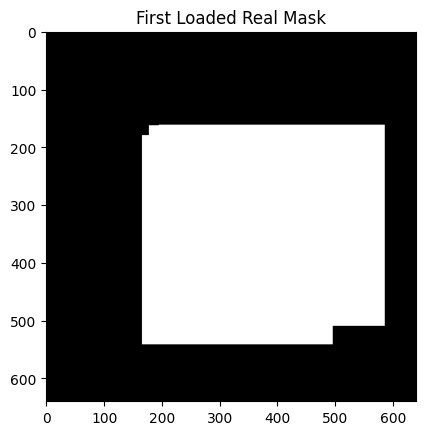

In [ ]:
import os
import numpy as np
import cv2

# Gerçek maskelerin yüklenip yüklenmediğini kontrol eden fonksiyon
def load_real_masks(val_labels_dir, img_height=640, img_width=640):
    real_masks = []
    for filename in os.listdir(val_labels_dir):
        if filename.endswith('.txt') and not filename.startswith('.'):
            label_path = os.path.join(val_labels_dir, filename)
            bboxes = np.loadtxt(label_path, delimiter=' ', usecols=range(1, 5))
            # bboxes bir liste halinde gelmeli, eğer tek bir bbox varsa bunu bir listeye çevirmeliyiz
            if bboxes.ndim == 1:
                bboxes = np.expand_dims(bboxes, axis=0)
            # Maskeyi oluştur
            mask_img = np.zeros((img_height, img_width), dtype=np.uint8)
            for bbox in bboxes:
                x_center, y_center, bbox_width, bbox_height = bbox
                x1 = int((x_center - bbox_width / 2) * img_width)
                y1 = int((y_center - bbox_height / 2) * img_height)
                x2 = int((x_center + bbox_width / 2) * img_width)
                y2 = int((y_center + bbox_height / 2) * img_height)
                mask_img[y1:y2, x1:x2] = 1  # Bounding box'ı maske olarak ekle
            real_masks.append(mask_img)
    return real_masks

# Gerçek maskeleri yükle
val_labels_dir = '/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/labels/val'
real_masks = load_real_masks(val_labels_dir)

# Yüklenen gerçek maskelerin doğruluğunu kontrol etmek için ilk maskeyi göster
import matplotlib.pyplot as plt
if real_masks:
    plt.imshow(real_masks[0], cmap='gray')
    plt.title('First Loaded Real Mask')
    plt.show()
else:
    print("No real masks were loaded.")


In [ ]:
# Karışıklık matrisi değerlerine göre IoU hesaplama
TP = 411  # Doğru Pozitifler
FP = 130  # Yanlış Pozitifler
FN = 102  # Yanlış Negatifler

# IoU hesaplaması
IoU = TP / (TP + FP + FN)
IoU


0.6391912908242613